In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import numpy as np
import pandas as pd
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT_DIR   = Path.cwd().parent.parent
ARIMA_RESULTS = ROOT_DIR / "data" / "results" / "arima_results.csv"
ARIMA_SUMMARY = ROOT_DIR / "data" / "results" / "arima_summary.csv"
OUT_DIR    = ROOT_DIR / "data" / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Đọc dữ liệu từ các file CSV
results_df = pd.read_csv(ARIMA_RESULTS)
summary_df = pd.read_csv(ARIMA_SUMMARY)

# Chuyển đổi cột Date sang định dạng datetime
results_df['Date'] = pd.to_datetime(results_df['Date'])

# Sắp xếp lại dữ liệu theo thời gian
results_df = results_df.sort_values(by=['ticker', 'Date'])

print("Dữ liệu Summary Metrics:")
display(summary_df.head())

print("\nDữ liệu Results:")
display(results_df.head())

Dữ liệu Summary Metrics:


,ticker,MAE,RMSE,DA,IC
0,ACB,0.892326,1.367600,0.410286,0.035400
1,BVH,3.239554,4.124197,0.345143,0.036902
2,CTG,1.336154,1.807740,0.443429,0.042532
3,FPT,6.120202,8.876323,0.379429,0.024345
4,GAS,3.027974,3.922321,0.474286,0.023515



Dữ liệu Results:


,Date,ticker,target,regime_hmm,pred
0,2022-07-01,ACB,14.099,Bear,14.030804
1,2022-07-04,ACB,14.216,Bear,14.067510
2,2022-07-05,ACB,14.333,Bear,14.033136
3,2022-07-06,ACB,14.187,Bear,14.065326
4,2022-07-07,ACB,14.157,Bear,14.035181


In [7]:
import plotly.graph_objects as go

# Chỉ lấy 10 dòng đầu cho đẹp nếu bảng quá dài
plot_df = summary_df.head(10).round(4) 

fig = go.Figure(data=[go.Table(
    header=dict(values=list(plot_df.columns),
                fill_color='midnightblue',
                font=dict(color='white', size=14),
                align='center',
                height=40),
    cells=dict(values=[plot_df[col] for col in plot_df.columns],
               fill_color='aliceblue',
               font=dict(color='black', size=12),
               align='center',
               height=30))
])

fig.update_layout(title_text="Summary Metrics ARIMA", title_x=0.5, margin=dict(l=0, r=0, t=40, b=0))
fig.show()

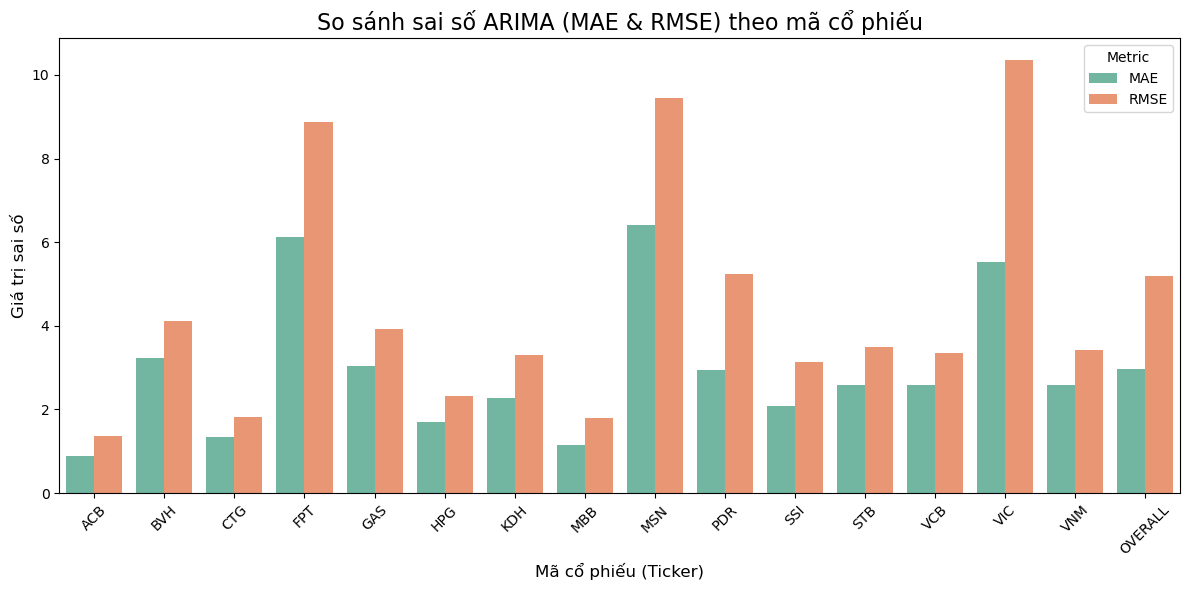

In [3]:
plt.figure(figsize=(12, 6))

# Chuyển đổi dữ liệu để vẽ biểu đồ cột nhóm
summary_melted_error = summary_df.melt(id_vars='ticker', 
                                       value_vars=['MAE', 'RMSE'], 
                                       var_name='Metric', 
                                       value_name='Value')

# Vẽ biểu đồ
sns.barplot(data=summary_melted_error, x='ticker', y='Value', hue='Metric', palette='Set2')
plt.title('So sánh sai số ARIMA (MAE & RMSE) theo mã cổ phiếu', fontsize=16)
plt.xlabel('Mã cổ phiếu (Ticker)', fontsize=12)
plt.ylabel('Giá trị sai số', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

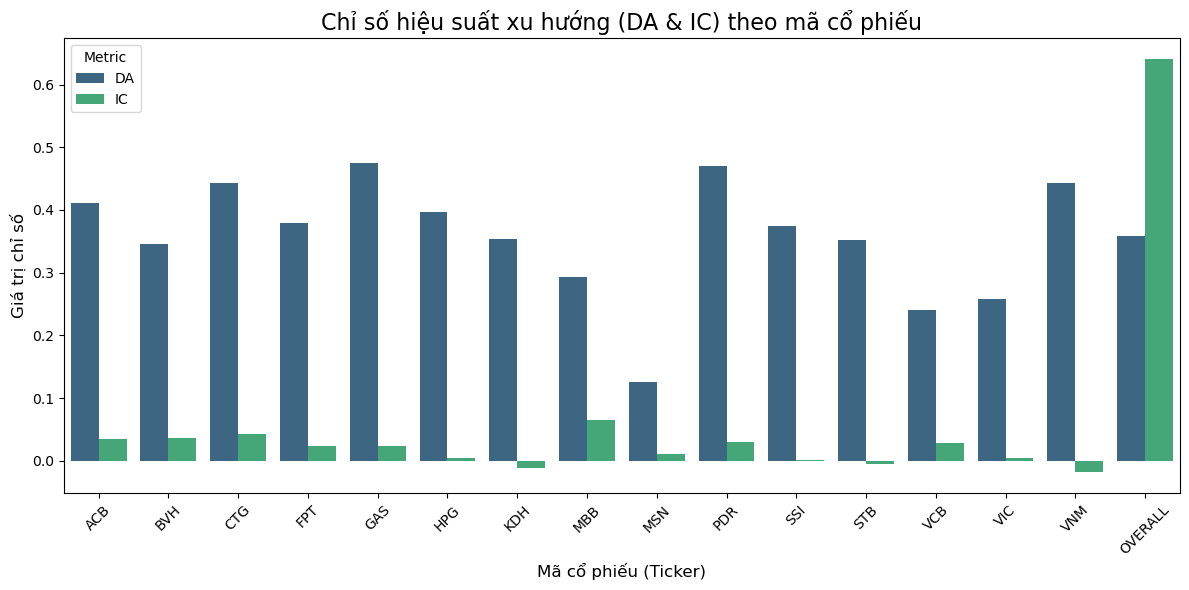

In [4]:
plt.figure(figsize=(12, 6))

summary_melted_perf = summary_df.melt(id_vars='ticker', 
                                      value_vars=['DA', 'IC'], 
                                      var_name='Metric', 
                                      value_name='Value')

sns.barplot(data=summary_melted_perf, x='ticker', y='Value', hue='Metric', palette='viridis')
plt.title('Chỉ số hiệu suất xu hướng (DA & IC) theo mã cổ phiếu', fontsize=16)
plt.xlabel('Mã cổ phiếu (Ticker)', fontsize=12)
plt.ylabel('Giá trị chỉ số', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

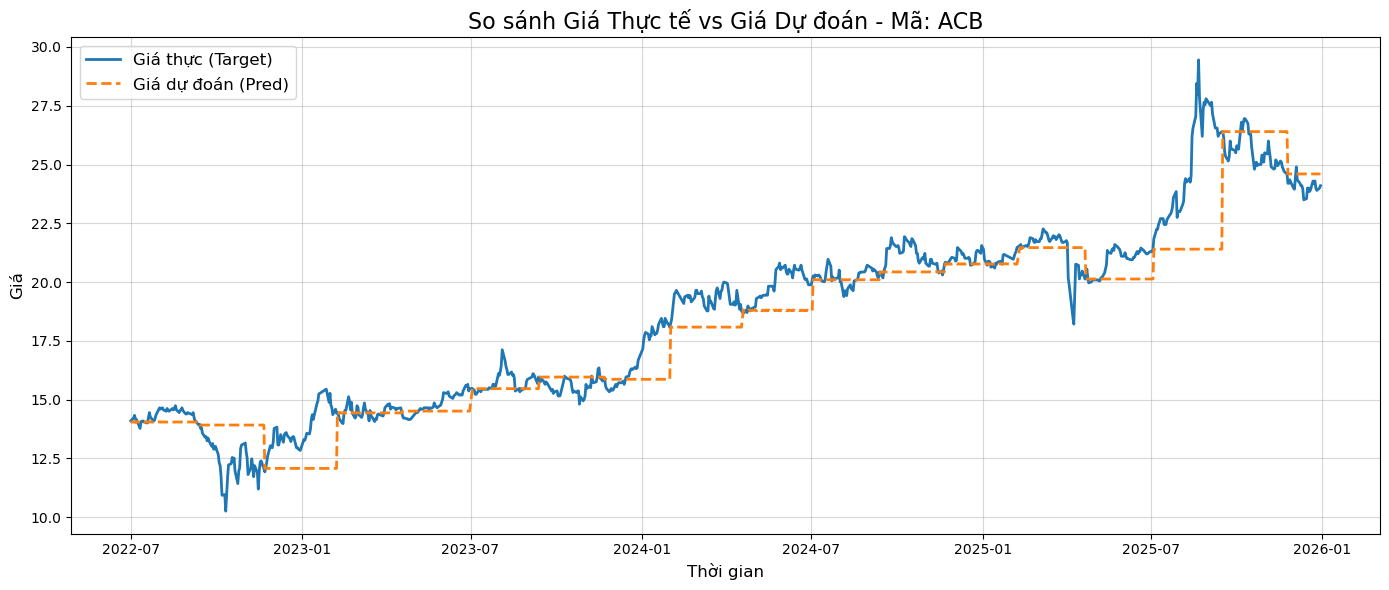

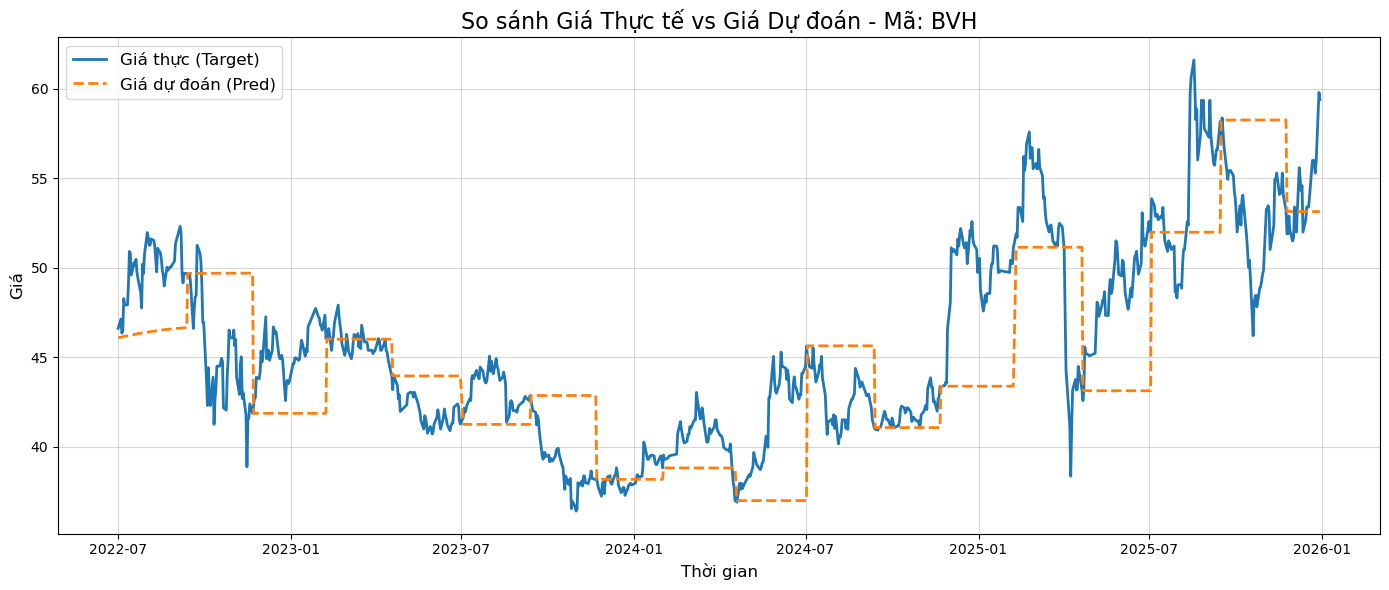

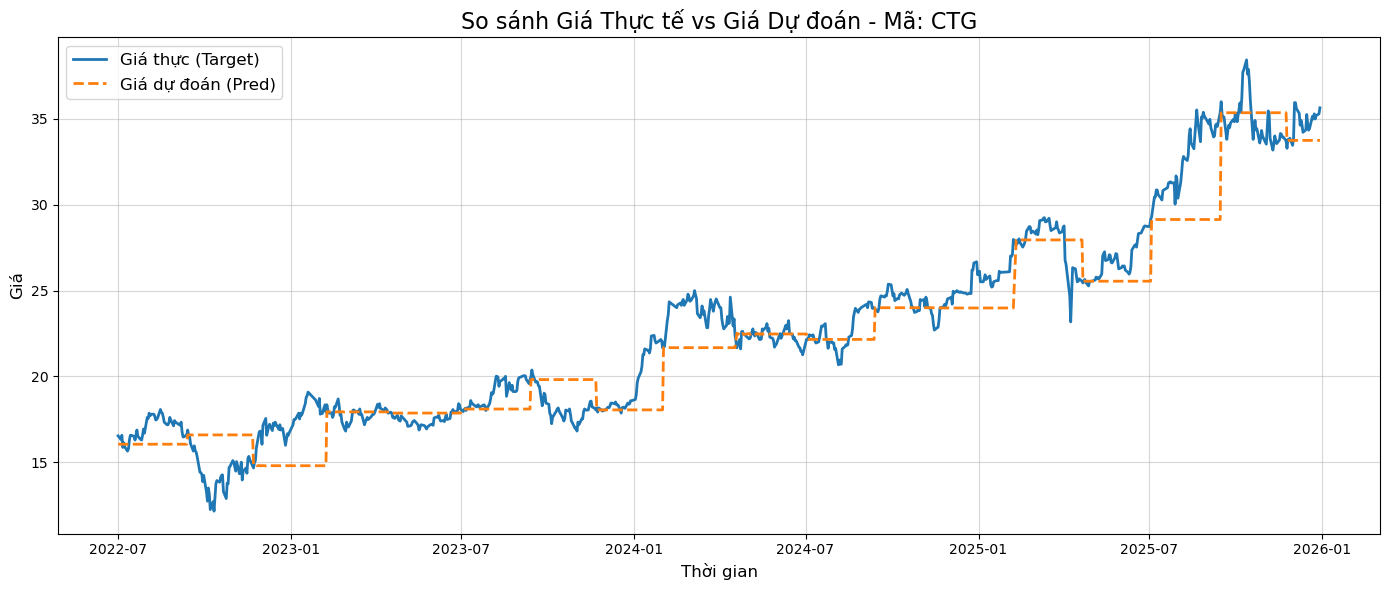

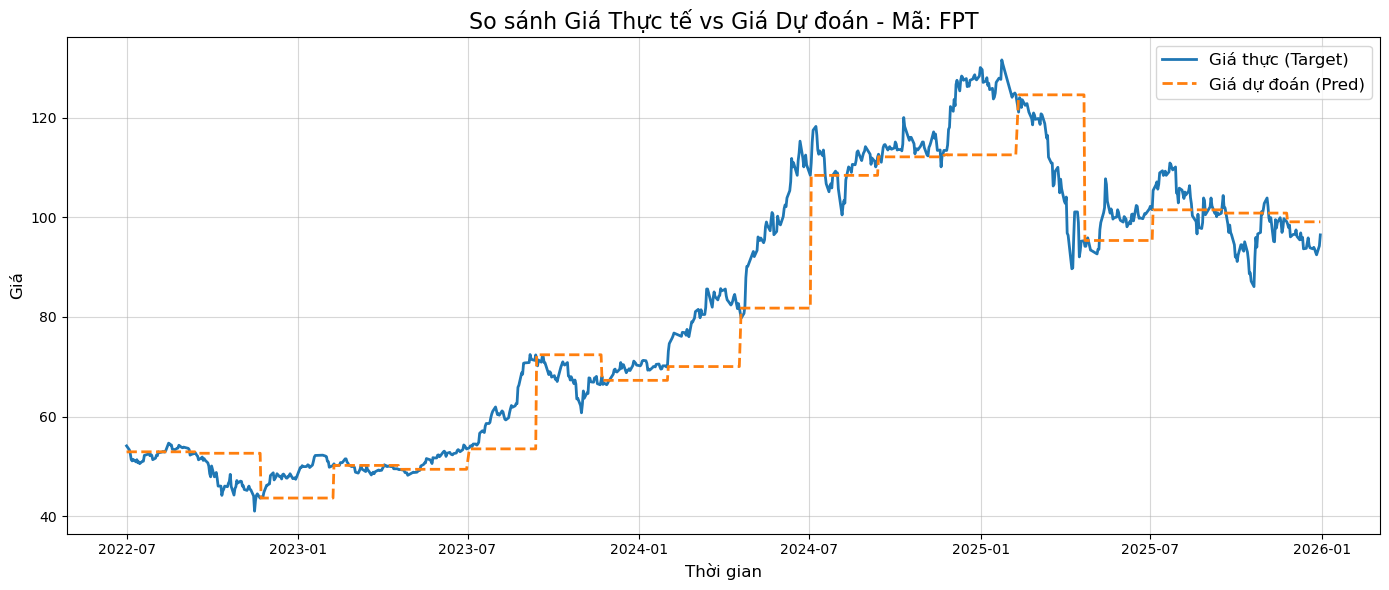

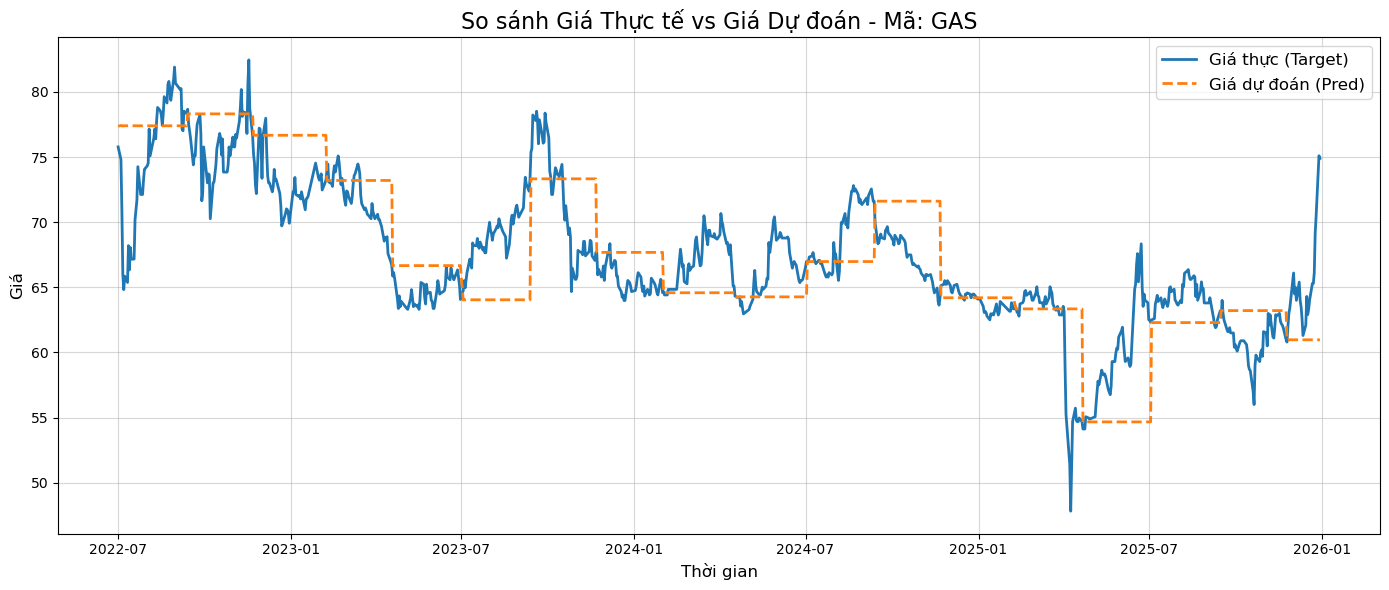

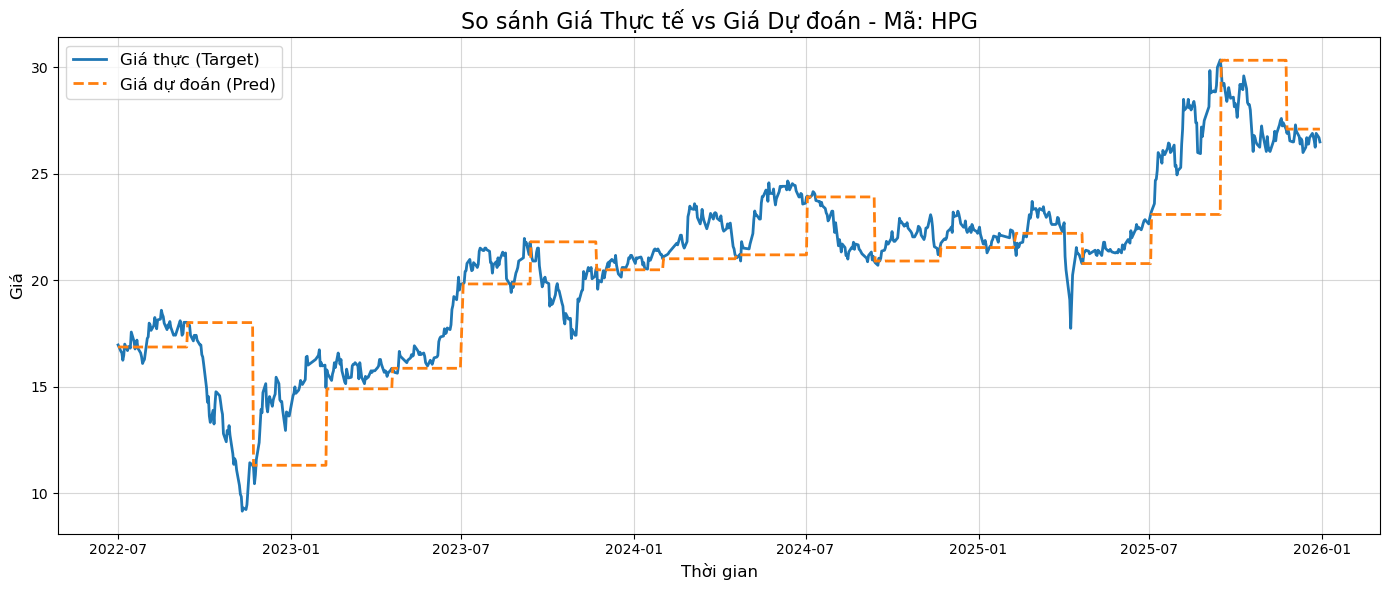

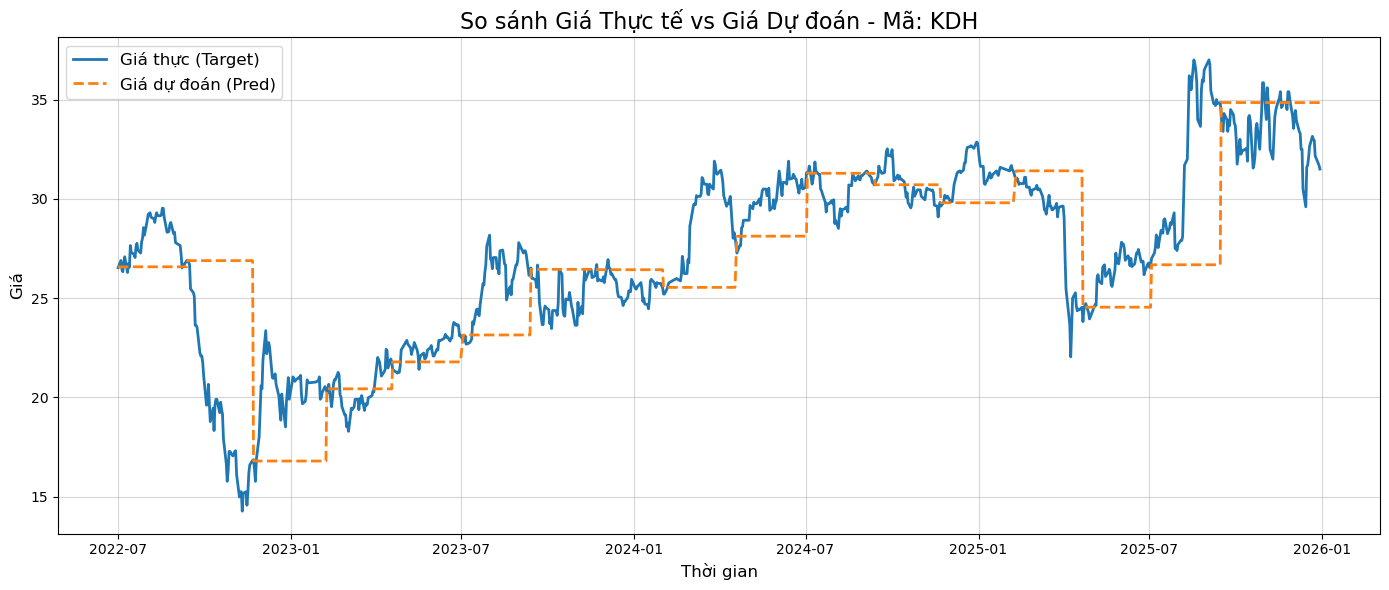

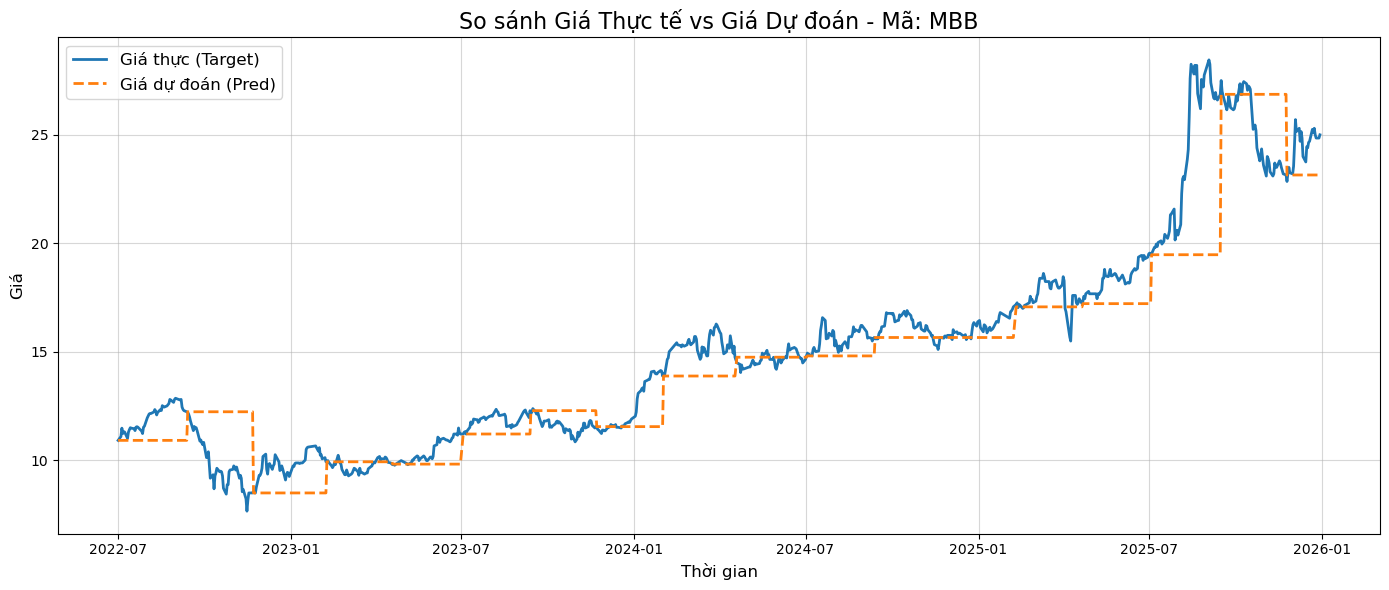

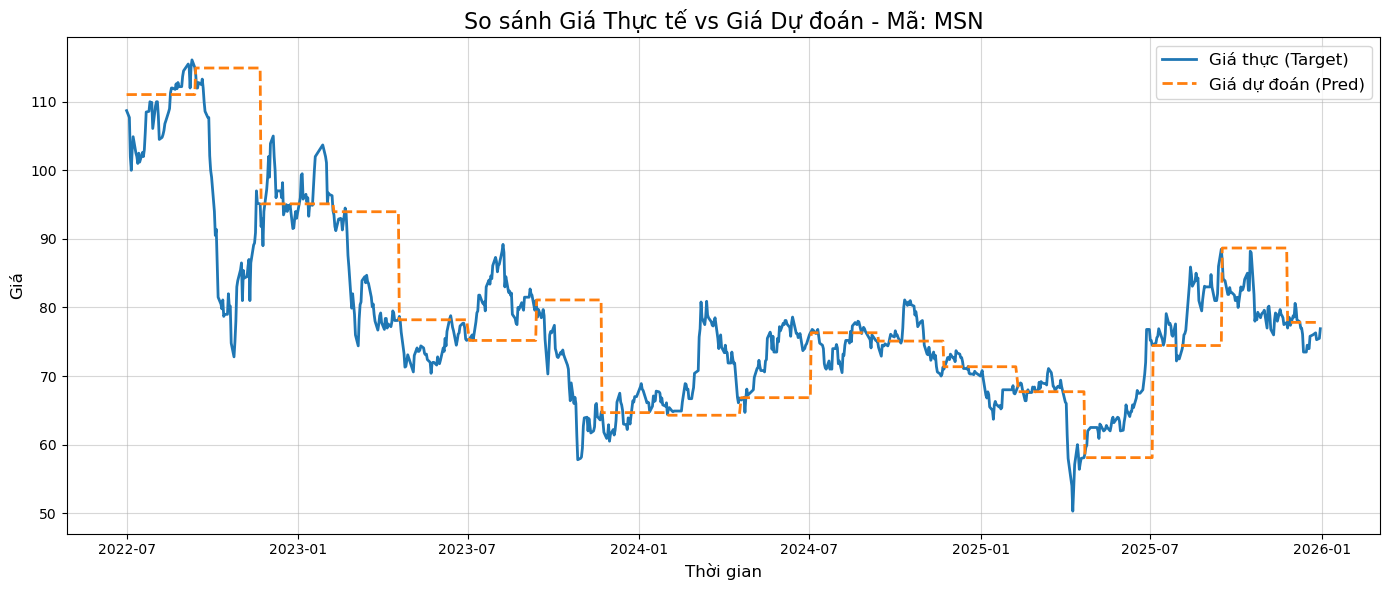

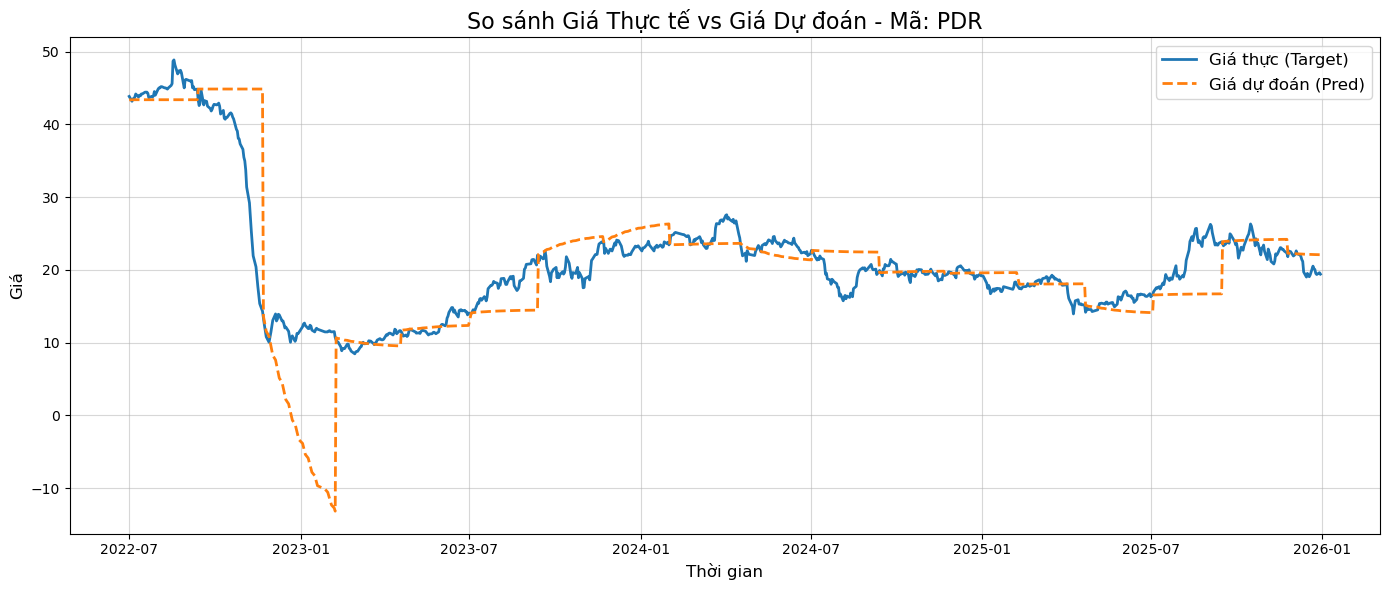

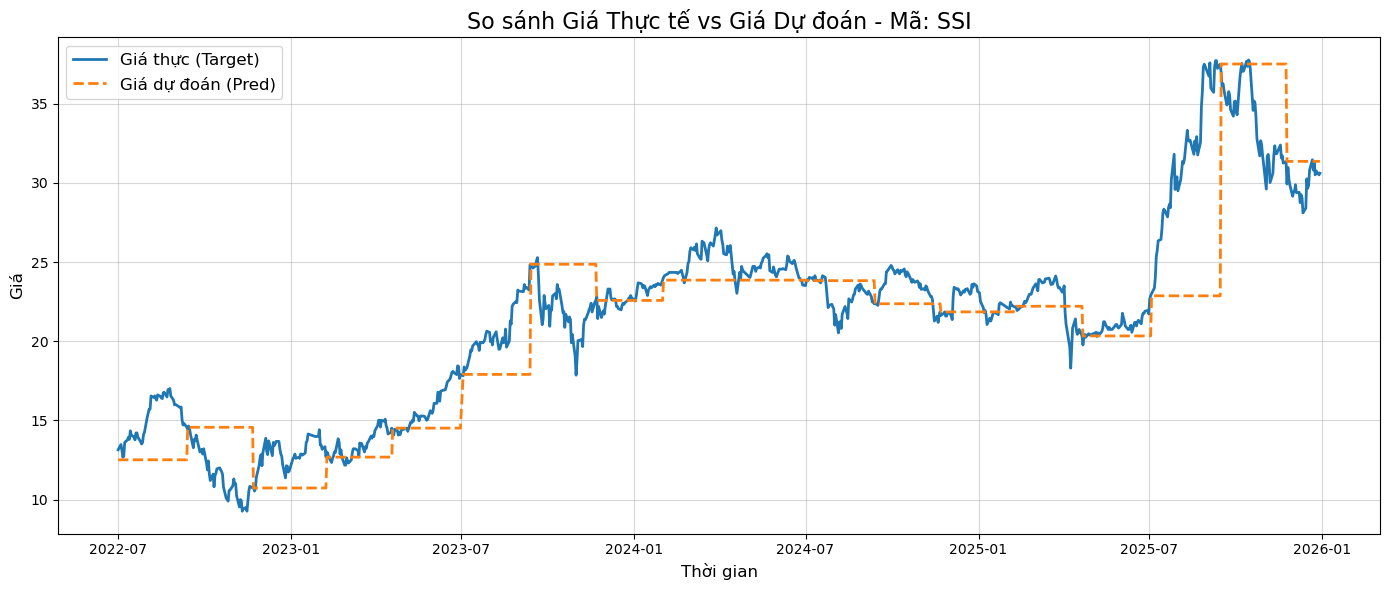

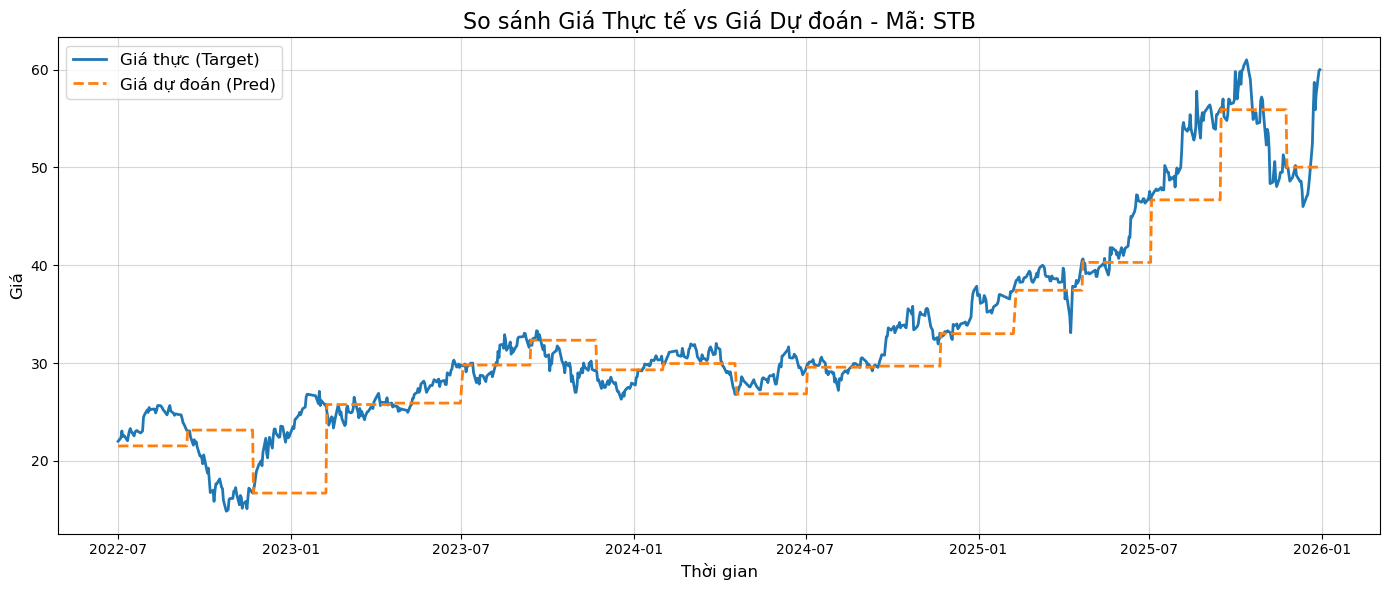

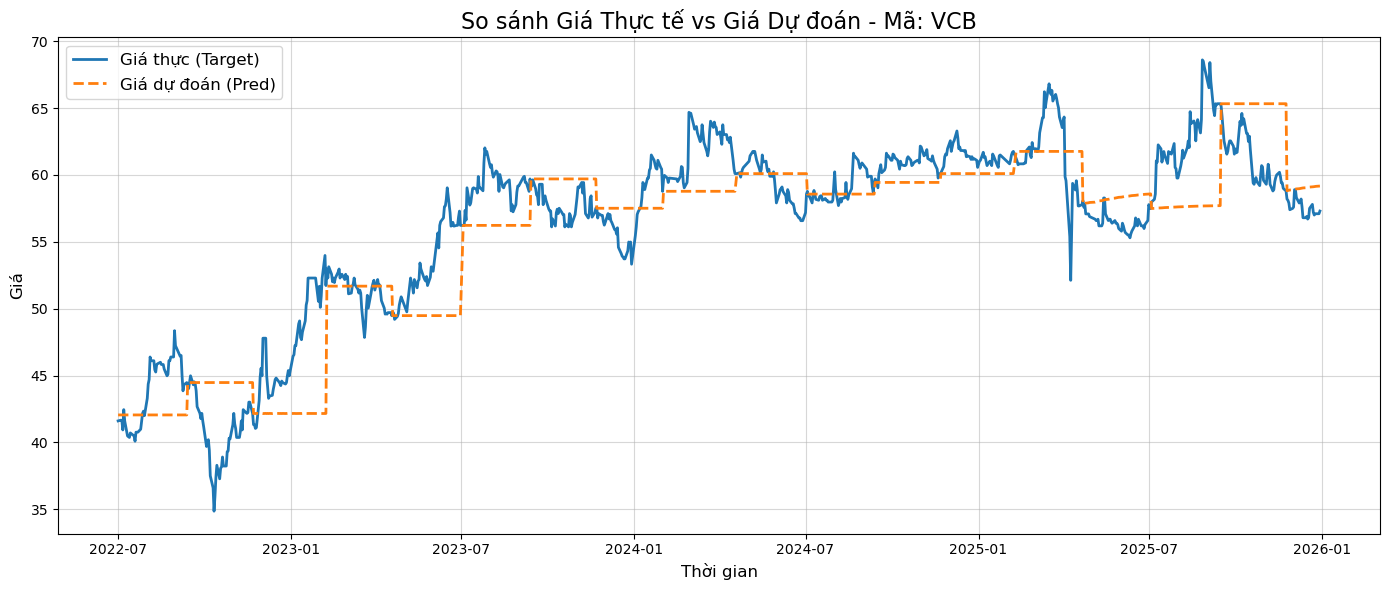

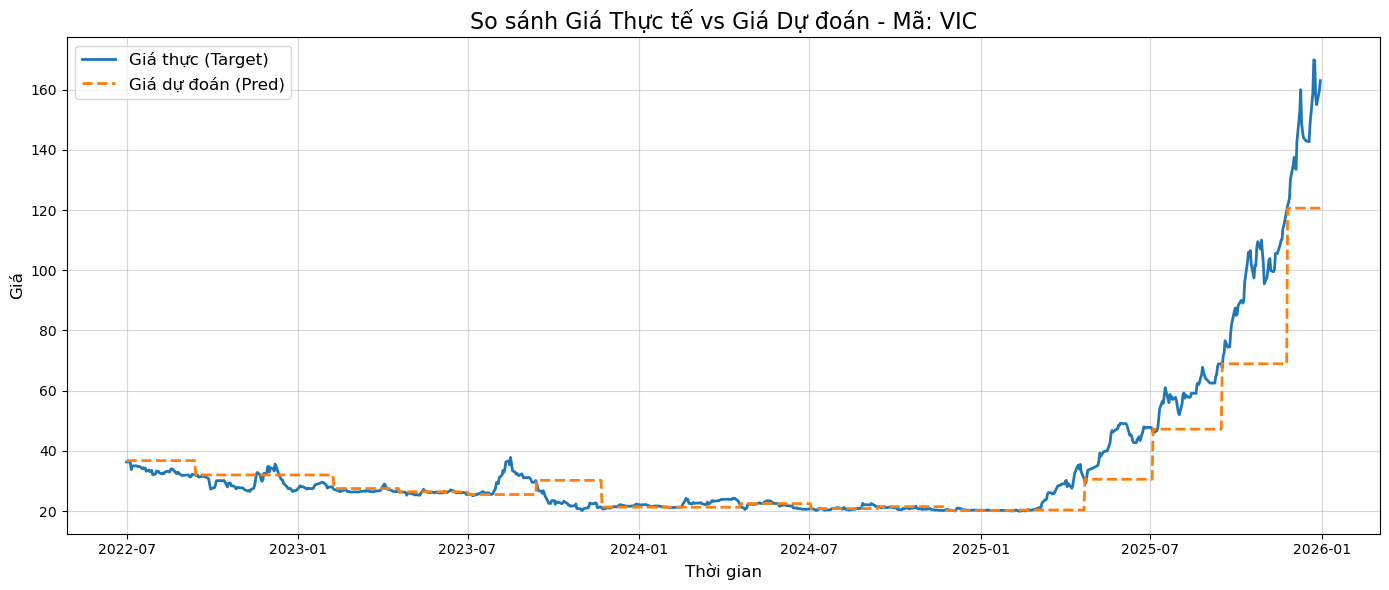

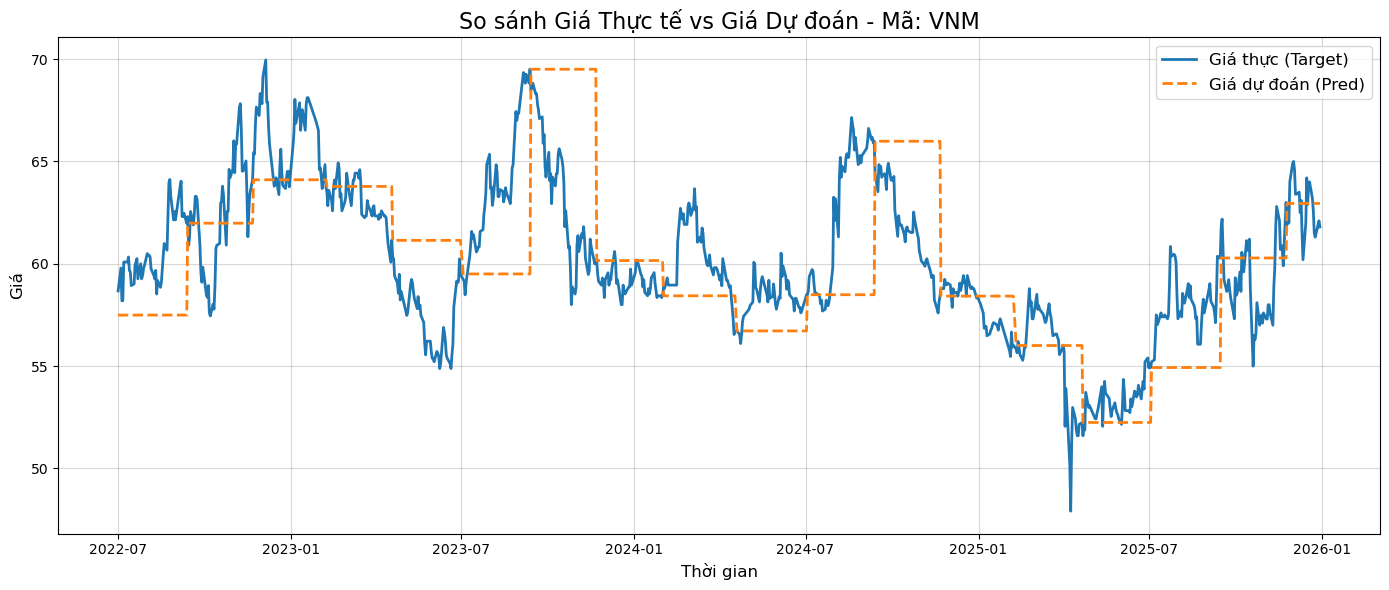

In [5]:
# Lấy danh sách các mã cổ phiếu có trong kết quả
tickers = results_df['ticker'].unique()

# Vẽ biểu đồ cho từng mã cổ phiếu
for ticker in tickers:
    # Lọc dữ liệu theo từng mã
    ticker_data = results_df[results_df['ticker'] == ticker]
    
    plt.figure(figsize=(14, 6))
    
    # Đường giá thực tế (Màu xanh đậm, nét liền)
    plt.plot(ticker_data['Date'], ticker_data['target'], label='Giá thực (Target)', color='#1f77b4', linewidth=2)
    
    # Đường giá dự đoán (Màu cam, nét đứt)
    plt.plot(ticker_data['Date'], ticker_data['pred'], label='Giá dự đoán (Pred)', color='#ff7f0e', linestyle='--', linewidth=2)
    
    # Định dạng biểu đồ
    plt.title(f'So sánh Giá Thực tế vs Giá Dự đoán - Mã: {ticker}', fontsize=16)
    plt.xlabel('Thời gian', fontsize=12)
    plt.ylabel('Giá', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.5)
    plt.tight_layout()
    plt.show()